# 01. 데이터 수집과 살펴보기

안녕하세요! 이 노트북은 **KBO 승패 예측 프로젝트의 첫 번째 이야기**예요.
모델을 만들기 전에 *어떤 데이터를, 어디서, 어떻게 모았는지*, 그리고 *모은 데이터가 어떻게 생겼는지*를 차근차근 보여 드릴게요.

### 이 노트북이 하는 일
- 경기 일정 페이지와 경기 결과 페이지를 한 장씩 직접 읽어서(파싱해서) 표로 바꿔 봐요.
- 2015~2026년 12개 시즌 데이터를 한꺼번에 불러와 경기 수와 상태를 확인해요.
- 정규시즌 경기가 시즌마다 정확히 720경기인지 검산하고, 그래프 3개로 데이터를 둘러봐요.
- 마지막으로 데이터의 빈틈(끝나지 않은 채 멈춘 경기, 취소된 경기 등)을 정리해요.

### 왜 필요한가요?
예측 모델은 데이터만큼만 똑똑해요. 경기가 빠지거나 잘못 들어가 있으면 아무리 좋은 모델도 엉뚱한 답을 내요.
그래서 모델 이야기를 시작하기 전에 "**이 데이터는 믿을 만하다**"는 걸 먼저 눈으로 확인해 두려는 거예요.

### 짝이 되는 `.py` 파일
이 노트북은 계산을 직접 새로 짜지 않고, `src/kbo_predict/` 안의 코드를 **불러서 쓰기만** 해요.
그래서 노트북에서 본 결과와 매일 도는 자동 수집(GitHub Actions)의 결과가 언제나 같아요.

| 파일 | 하는 일 |
|---|---|
| `collect.py` | 날짜 범위를 일주일씩 돌면서 경기 일정과 결과를 모아 저장해요 |
| `mykbo_parse.py` | 내려받은 HTML 페이지를 읽어 경기·선수 기록(파이썬 dict)으로 바꿔요 |
| `raw_store.py` | 파싱한 결과를 `data/raw/` 아래 JSON 파일로 저장하고 다시 불러와요 |

그 밖에 `seasons.py`에는 시즌별 정규시즌 날짜가, `teams.py`에는 구단 코드가 들어 있어요.

### 읽는 순서
1. 준비
2. 데이터는 어디서 왔을까?
3. 주간 일정 페이지 한 장 읽기
4. 경기 페이지 한 장 읽기
5. 실제로 모을 때는 이렇게 (실행하지 않는 예시)
6. 전체 시즌 불러오기
7. 정규시즌 범위와 720경기 검산
8. 그래프로 살펴보기
9. 데이터 품질 메모
10. 요약과 다음 이야기

> 처음 보시는 분은 위에서부터 차례로 읽으시면 돼요. 결과만 궁금하시면 7~9번만 보셔도 충분해요.
> 이 노트북은 인터넷 없이도 끝까지 실행돼요. 이미 모아 둔 데이터와 저장해 둔 예시 페이지만 읽거든요.

## 1. 준비

먼저 노트북이 프로젝트 코드와 데이터를 찾을 수 있게 길을 알려 줘요.

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위(`Path.cwd().parent`)가 프로젝트 루트예요.
- `src/`를 파이썬 경로에 넣어서 `kbo_predict` 패키지를 불러올 수 있게 해요.
- `KBO_DATA_DIR` 환경변수로 데이터 폴더(`data/`)를 알려 줘요. `raw_store`가 이 값을 보고 파일을 찾아요.
- 그래프의 한글이 깨지지 않도록 한글 폰트를 지정해요. 컴퓨터에 없는 폰트는 건너뛰고 다음 후보를 써요.

**출력 보는 법:** 데이터 폴더가 있고 시즌 목록(2015~2026)이 보이면 준비 끝이에요.

In [1]:
import logging
import os
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
os.environ.setdefault("KBO_DATA_DIR", str(ROOT / "data"))  # raw_store가 데이터를 찾는 폴더

# 그래프 한글 폰트: 윈도우 → 맥 → 리눅스(나눔) → 기본 폰트 순으로 있는 것을 써요
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False                 # 마이너스 기호가 네모로 깨지지 않게
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
pd.set_option("display.width", 120)

from kbo_predict import raw_store

print("데이터 폴더가 있나요?:", (raw_store.data_dir() / "raw").exists())
print("저장된 시즌          :", raw_store.available_seasons())

데이터 폴더가 있나요?: True
저장된 시즌          : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


## 2. 데이터는 어디서 왔을까?

아쉽게도 KBO는 누구나 쓸 수 있는 **공개 API**(프로그램이 데이터를 받아 가는 공식 창구)를 제공하지 않아요.
네이버 스포츠에는 기록이 잘 정리되어 있지만 브라우저가 아닌 프로그램의 접근을 막고 있어서, 그 차단을 굳이 우회하지 않기로 했어요. KBO 공식 홈페이지는 이용약관에서 자동 수집(크롤링)을 금지하고 있어서 역시 쓰지 않았어요.
그래서 KBO 경기 기록을 영어로 정리해 두는 **MyKBOStats**(mykbostats.com)를 골랐고, 이 사이트의 `robots.txt`(사이트가 "로봇은 이렇게 다녀가 주세요"라고 적어 둔 안내문)에 있는 **요청 사이 5초 쉬기**(Crawl-delay 5초) 규칙을 지키며, 우리가 누구인지 밝히는 User-Agent를 달고 천천히 받아 왔어요.
내려받은 원본 HTML은 내 컴퓨터의 `data/cache/html/`에만 두고 Git에는 올리지 않아요(`.gitignore`로 제외). 남의 사이트 페이지를 통째로 다시 퍼뜨리지 않기 위해서이고, 저장소에는 우리가 직접 뽑아낸 **파싱 결과**(JSON)만 커밋해요.

아래 셀은 이 약속이 말로만이 아니라 실제 코드(`mykbo_client.py`)에 들어 있는지 확인해요.

**출력 보는 법:** 접속 주소, 우리를 소개하는 User-Agent, 요청 사이에 쉬는 시간(초)이 나와요.

In [2]:
from kbo_predict import mykbo_client

print("접속 주소        :", mykbo_client.BASE_URL)
print("User-Agent       :", mykbo_client.USER_AGENT)
print("요청 간격(초)    :", mykbo_client.SLEEP_S)
print("원본 HTML 보관   : data/cache/html/  (Git에 올리지 않음)")

접속 주소        : https://mykbostats.com
User-Agent       : Mozilla/5.0 (compatible; kbo-predict/0.1; +https://github.com/kimminseo2323-prog/2610_KBO_predict)
요청 간격(초)    : 5.0
원본 HTML 보관   : data/cache/html/  (Git에 올리지 않음)


## 3. 주간 일정 페이지 한 장 읽기

MyKBOStats는 **일주일치 경기 일정**을 한 페이지에 보여 줘요. 수집은 늘 이 주간 일정 페이지에서 시작해요.
여기서 경기 번호(`game_id`), 날짜, 맞붙는 두 팀, 점수, 경기 상태를 얻고, 끝난 경기만 골라 경기 페이지를 따로 받아요.

여기서는 인터넷에 접속하지 않고, 테스트용으로 저장해 둔 실제 페이지 `tests/fixtures/mykbo_week_2026-10-27.html`을 `parse_week`로 읽어요.
2026년 10월 27일이 들어 있는 주인데, 이때는 **포스트시즌**(정규시즌이 끝난 뒤 상위 팀끼리 우승을 다투는 '가을야구') 기간이라 KIA와 삼성의 경기만 있어요.

**출력 보는 법:** 한 줄이 한 경기예요. 이미 끝난 경기는 `FINAL`과 점수가, 아직 열리지 않은 경기는 `SCHEDULED`와 시작 시각·구장이 채워져 있어요.
점수 칸의 `<NA>`는 "값 없음(None)"을 판다스가 보여 주는 방식이에요.

In [3]:
from kbo_predict.mykbo_parse import parse_week

FIXTURES = ROOT / "tests" / "fixtures"
COLS = ["game_id", "date", "away", "home", "away_code", "home_code",
        "away_score", "home_score", "status", "time_kst", "stadium"]
SCORE_INT = {"away_score": "Int64", "home_score": "Int64"}  # 화면에 3.0 대신 3으로 보이게

week_html = (FIXTURES / "mykbo_week_2026-10-27.html").read_text(encoding="utf-8")
week = pd.DataFrame(parse_week(week_html))
display(week[COLS].astype(SCORE_INT))

,game_id,date,away,home,away_code,home_code,away_score,home_score,status,time_kst,stadium
0,14052,2026-10-27,Kia Tigers,Samsung Lions,HT,SS,3,8,FINAL,None,None
1,14050,2026-10-29,Samsung Lions,Kia Tigers,SS,HT,<NA>,<NA>,SCHEDULED,18:30,Gwangju
2,14053,2026-10-30,Samsung Lions,Kia Tigers,SS,HT,<NA>,<NA>,SCHEDULED,18:30,Gwangju
3,14054,2026-11-01,Kia Tigers,Samsung Lions,HT,SS,<NA>,<NA>,SCHEDULED,14:00,Daegu


### 컬럼 뜻

| 컬럼 | 뜻 |
|---|---|
| `game_id` | MyKBOStats가 경기마다 붙인 고유 번호예요. 경기 페이지 주소(`path`)에도 들어가요. |
| `date` | **한국 시간** 기준 경기 날짜예요. 사이트는 세계 표준시(`datetime_utc`)로 주는데, 한국 시간으로 바꿔서 날짜를 정해요. `season`은 이 날짜의 연도예요. |
| `home` / `away` | **홈팀**(자기 구장에서 경기하는 팀)과 **원정팀**(찾아온 팀)이에요. 야구에서는 원정팀이 먼저 공격하는 '초', 홈팀이 나중에 공격하는 '말'로 한 이닝이 나뉘어요. |
| `home_code` / `away_code` | KBO 구단 코드예요(예: `SS` = 삼성, `HT` = KIA). 팀 이름이 바뀌어도 코드는 그대로라서, 여러 시즌을 이어 볼 때 이 코드를 기준으로 써요. |
| `home_score` / `away_score` | 최종 점수예요. 끝나지 않았거나 취소된 경기는 0이 아니라 `None`이에요. |
| `status` | 경기 상태: `FINAL`(끝남), `SCHEDULED`(예정), `LIVE`(진행 중), `CANCELED`(비·미세먼지 등으로 취소) |
| `status_note` | 취소 사유예요(예: `Rained Out` = 우천 취소). |
| `time_kst` | 경기 시작 시각(한국 시간)이에요. 일정 페이지가 **예정 경기에만** 보여 줘서, 지난 경기에는 비어 있어요. |
| `stadium` | 구장이 있는 도시예요. `time_kst`처럼 예정 경기에만 표시돼요. |

### 구단 코드 한눈에 보기

`teams.py`의 `TEAMS`에는 사이트에 나오는 영어 팀 이름과 구단 코드가 정리되어 있어요.
**넥센 히어로즈**(2015~2018)는 지금의 키움 히어로즈와, **SK 와이번스**(2015~2020)는 지금의 SSG 랜더스와 같은 코드를 써요.
덕분에 팀 이름이 바뀌어도 한 팀의 기록이 끊기지 않고 이어져요.

**출력 보는 법:** 영어 이름 12개가 코드 10개로 모이는 걸 볼 수 있어요(KBO는 10개 구단이에요).

In [4]:
from kbo_predict.teams import TEAMS

team_table = pd.DataFrame(
    [{"코드": info["code"], "영어 이름": name, "한글 이름": info["ko"]} for name, info in TEAMS.items()]
)
display(team_table.sort_values(["코드", "영어 이름"]).reset_index(drop=True))

,코드,영어 이름,한글 이름
0,HH,Hanwha Eagles,한화
1,HT,Kia Tigers,KIA
2,KT,KT Wiz,KT
3,LG,LG Twins,LG
4,LT,Lotte Giants,롯데
5,NC,NC Dinos,NC
6,OB,Doosan Bears,두산
7,SK,SK Wyverns,SK
8,SK,SSG Landers,SSG
9,SS,Samsung Lions,삼성


## 4. 경기 페이지 한 장 읽기

끝난 경기의 페이지에는 **박스스코어**(두 팀 선수 한 명 한 명의 그날 기록을 모은 표)가 있어요.
이번에는 저장해 둔 `tests/fixtures/mykbo_game_14048_final.html`(2026-10-26, KIA vs 삼성)을 `parse_game`으로 읽어요.

먼저 경기의 기본 정보부터 볼게요. **이닝**은 두 팀이 한 번씩 공격하는 단위이고, 야구는 보통 9이닝까지 해요.
`linescore`는 이닝별 득점이에요.

**출력 보는 법:** 원정팀 KIA가 5점, 홈팀 삼성이 1점이에요. 이닝별 득점을 더하면 최종 점수와 같아요.

In [5]:
from kbo_predict.mykbo_parse import parse_game

box = parse_game((FIXTURES / "mykbo_game_14048_final.html").read_text(encoding="utf-8"))
print("game_id:", box["game_id"], "| 날짜:", box["date"], "| 구장:", box["stadium"], "| 상태:", box["status"])
for side in ("away", "home"):
    team = box[side]
    print(f"{side:>4}: {team['name']} ({team['code']}) {team['score']}점 | 이닝별 득점 {box['linescore'][side]}")

game_id: 14048 | 날짜: 2026-10-26 | 구장: Daegu Samsung Lions Park | 상태: FINAL
away: Kia Tigers (HT) 5점 | 이닝별 득점 [2, 0, 2, 1, 0, 0, 0, 0, 0]
home: Samsung Lions (SS) 1점 | 이닝별 득점 [0, 0, 0, 0, 1, 0, 0, 0, 0]


### 타자 기록

원정팀(KIA) 타자 표예요. `order`는 **타순**(타석에 들어서는 순서, 1~9번)이에요.
경기 중간에 바꿔 들어온 교체 선수는 앞 선수의 타순을 이어받아서, 같은 번호가 두 번 나올 수 있어요(예: 5번 Na Sung-bum → Kim Ho-ryung).

| 컬럼 | 뜻 |
|---|---|
| `player_id`, `name` | 사이트의 선수 번호와 이름 |
| `pos` | 수비 위치 (C 포수, 1B 1루수, 2B 2루수, 3B 3루수, SS 유격수, LF·CF·RF 좌익수·중견수·우익수, DH 지명타자 = 수비 없이 타격만 하는 선수) |
| `ab` | 타수: 타석에 선 횟수 중 볼넷·몸에 맞는 공 등을 뺀 횟수 |
| `r` / `h` / `hr` | 득점(홈을 밟은 횟수) / 안타 / 홈런 |
| `rbi` | 타점: 내 타격으로 팀이 얻은 점수 |
| `bb` / `so` / `hbp` | 볼넷(볼 4개로 1루에 나감) / 삼진 / 몸에 맞는 공 |

**출력 보는 법:** 4번 타자 Castro가 4타수 3안타(홈런 1개) 3타점으로 이 경기의 주인공이었네요.

In [6]:
display(pd.DataFrame(box["batting"]["away"]))

,order,player_id,name,pos,ab,r,h,hr,rbi,bb,so,hbp
0,1,1555,Park Jung-woo,RF,5,0,0,0,0,0,2,0
1,2,2768,Park Jae-hyun,LF,4,0,0,0,0,0,2,0
2,3,2281,Kim Do-yeong,3B,3,2,2,0,0,1,0,0
3,4,2949,Castro,1B,4,2,3,1,3,0,0,0
4,5,532,Na Sung-bum,RF,3,0,1,0,1,1,0,0
5,5,1013,Kim Ho-ryung,CF,0,0,0,0,0,0,0,0
6,6,268,Kim Sun-bin,2B,3,0,0,0,0,1,1,0
7,6,1366,Kim Kyu-sung,2B,0,0,0,0,0,0,0,0
8,7,1664,Han Jun-su,DH,4,1,1,1,1,0,1,0
9,8,530,Kim Tae-gun,C,4,0,0,0,0,0,0,0


### 투수 기록과 "이닝을 아웃 수로 저장하기"

홈팀(삼성) 투수 표예요. `order`는 마운드에 오른 순서, `np`는 투구 수, `r`은 실점,
`er`은 **자책점**(수비 실책의 도움 없이 투수 책임으로 내준 점수), `h`·`hr`은 맞은 안타·홈런, `so`는 잡아낸 삼진, `bb`·`hbp`는 내준 볼넷·몸에 맞는 공이에요.

가장 눈여겨볼 컬럼은 `ip_outs`예요. 투수가 던진 이닝(IP)은 보통 "4 ⅔"처럼 분수로 적어요.
한 이닝에 아웃이 3개라서 ⅓이닝은 아웃 1개를 뜻하거든요. 이걸 4.67 같은 소수로 바꾸면 여러 경기를 더할 때 반올림 오차가 쌓여요.
그래서 아예 **잡아낸 아웃 수**(정수)로 저장해요. 선발 투수 Paddack의 `14`는 4 ⅔이닝(4 × 3 + 2)이에요.

**출력 보는 법:** `ip_outs`를 3으로 나누면 익숙한 이닝이 돼요.

In [7]:
display(pd.DataFrame(box["pitching"]["home"]))

,order,player_id,name,ip_outs,np,r,er,h,hr,so,bb,hbp
0,1,3097,Paddack,14,94,5,5,5,2,4,2,0
1,2,2756,Bae Chan-seung,4,28,0,0,1,0,1,0,0
2,3,462,Kim Tae-hoon,3,9,0,0,0,0,1,0,0
3,4,1956,Lee Seung-min,3,17,0,0,1,0,0,1,0
4,5,3103,Miyamori Satoshi,3,16,0,0,0,0,1,0,0


이 변환을 해 주는 함수가 `parse_innings`예요. 몇 가지 입력을 직접 넣어 볼게요. 빈 칸은 0아웃으로 봐요.

그리고 하나 더! 박스스코어의 숫자 칸에 `-`처럼 숫자가 아닌 값이 있으면, 파서는 그 칸을 0이 아니라 **기록 없음**(`None`)으로 저장해요.
"0개를 기록했다"와 "기록이 없다"는 뜻이 달라서, 둘을 섞으면 평균 같은 계산이 틀어지기 때문이에요(9번에서 실제 데이터로 다시 확인해요).

**출력 보는 법:** 왼쪽이 페이지에 적힌 이닝, 오른쪽이 저장되는 아웃 수예요. `"4 ⅓"`은 4 × 3 + 1 = 13아웃이에요.

In [8]:
from kbo_predict.mykbo_parse import parse_innings

for text in ["4 ⅓", "4 ⅔", "6", "⅓", ""]:
    print(f"{text!r:>7} → {parse_innings(text):>2}아웃")

assert parse_innings("4 ⅓") == 13  # 4이닝(12아웃) + ⅓이닝(1아웃)

  '4 ⅓' → 13아웃
  '4 ⅔' → 14아웃
    '6' → 18아웃
    '⅓' →  1아웃
     '' →  0아웃


## 5. 실제로 모을 때는 이렇게 (실행하지 않는 예시)

지금까지는 저장해 둔 페이지로 연습했어요. 실제 수집은 `collect.collect_range`가 해요.
시작일부터 7일씩 건너뛰며 주간 일정 페이지를 받고, 그 주에 끝난(`FINAL`) 경기 중 **아직 박스스코어가 없는 경기만** 골라 경기 페이지를 받아 저장해요.
이미 받은 경기는 건너뛰니까, 중간에 멈췄다가 다시 돌려도 이어서 받아요. `season_range(2015)`는 시범경기와 포스트시즌까지 넉넉히 담도록 3월 1일~11월 30일을 돌려줘요.

이 셀은 인터넷에 접속하지 않도록 `DO_FETCH = False`로 막아 두었어요. `True`로 바꾸면 2015 시즌 전체를 실제로 받아요.

**왜 한 시즌에 약 1시간이 걸릴까요?** 한 시즌은 주간 일정 페이지 약 40장 + 경기 페이지 약 800장이에요(시범경기·포스트시즌 포함).
요청마다 5초씩 쉬니까 840번 × 5초 = 4,200초, 약 70분이에요. 더 빨리 받을 수도 있지만, 사이트에 부담을 주지 않는 게 먼저예요.

**출력 보는 법:** 수집을 건너뛰었다는 안내와 수집 범위, 실행했을 때의 예상 시간이 나와요.

In [9]:
from kbo_predict.collect import collect_range, season_range

DO_FETCH = False  # True로 바꾸면 실제로 인터넷에서 받아요 (약 1시간)

start, end = season_range(2015)
if DO_FETCH:
    result = collect_range(*season_range(2015), season=2015)
    print(result)  # {'weeks': ..., 'games': ..., 'boxscores': ..., 'errors': [...]}
else:
    n_requests = 40 + 800  # 주간 일정 약 40장 + 경기 페이지 약 800장
    minutes = n_requests * mykbo_client.SLEEP_S / 60
    print(f"DO_FETCH = False → 이번에는 수집을 건너뛰었어요. (수집 범위: {start} ~ {end})")
    print(f"실행한다면: 요청 약 {n_requests}번 × {mykbo_client.SLEEP_S:.0f}초 ≈ {minutes:.0f}분")

DO_FETCH = False → 이번에는 수집을 건너뛰었어요. (수집 범위: 2015-03-01 ~ 2015-11-30)
실행한다면: 요청 약 840번 × 5초 ≈ 70분


## 6. 전체 시즌 불러오기

이제 실제로 모아 둔 데이터를 불러와요. `available_seasons()`로 저장된 시즌을 찾고, 시즌마다 `load_games()`로 경기 목록을 읽어 하나의 표(DataFrame)로 합쳐요.
경기 목록은 `data/raw/<시즌>/games.jsonl`에 한 줄에 한 경기씩 들어 있어요.

**출력 보는 법:** 전체 행 수와 처음 세 줄이 나와요. **시범경기**(정규시즌 전에 치르는 연습 경기, 순위에 안 들어가요), 정규시즌, 포스트시즌, 취소된 경기까지 사이트에 있던 경기가 모두 들어 있어요.

In [10]:
seasons = raw_store.available_seasons()
games = pd.DataFrame([g for s in seasons for g in raw_store.load_games(s)])

print(f"시즌 {seasons[0]}~{seasons[-1]} ({len(seasons)}개 시즌), 전체 {len(games):,}행")
display(games[["season"] + COLS].head(3).astype(SCORE_INT))

시즌 2015~2026 (12개 시즌), 전체 10,382행


,season,game_id,date,away,home,away_code,home_code,away_score,home_score,status,time_kst,stadium
0,2015,838,2015-03-07,Kia Tigers,NC Dinos,HT,NC,1,2,FINAL,None,None
1,2015,839,2015-03-07,KT Wiz,Nexen Heroes,KT,WO,0,5,FINAL,None,None
2,2015,840,2015-03-07,LG Twins,Hanwha Eagles,LG,HH,3,9,FINAL,None,None


시즌별로 경기 상태가 어떻게 나뉘는지 **교차표**(행은 시즌, 열은 상태, 칸은 경기 수)로 볼게요.

**출력 보는 법:** 시즌마다 FINAL이 720보다 많은 건 시범경기와 포스트시즌이 함께 들어 있어서예요(정규시즌만 세는 건 7번에서 해요).
LIVE와 SCHEDULED는 아주 적어요. 이 행들은 바로 아래와 9번에서 하나씩 들여다볼게요.

In [11]:
status_table = pd.crosstab(games["season"], games["status"], margins=True, margins_name="합계")
display(status_table)

status,CANCELED,FINAL,LIVE,SCHEDULED,합계
season,,,,,
2015,91,795,0,0,886
2016,72,815,0,0,887
2017,43,793,0,0,836
2018,51,767,0,0,818
2019,69,769,0,0,838
2020,73,763,0,0,836
2021,154,767,0,0,921
2022,66,801,1,0,868
2023,98,800,1,3,902


`SCHEDULED`(예정)로 남아 있는 행은 어떤 경기일까요?
2023~2025년 3월 시범경기 중 사이트에 결과가 끝내 올라오지 않은 7경기와, 데이터를 모은 시점에 아직 열리지 않은 2026년 10월 말 포스트시즌 3경기예요.
모두 정규시즌 밖이라 모델 학습에는 영향이 없어요.

**출력 보는 법:** 날짜가 3월(시범경기) 아니면 10월 말 이후(포스트시즌)인지 보시면 돼요.

In [12]:
display(games.loc[games["status"] == "SCHEDULED", ["game_id", "date", "away_code", "home_code", "status"]])

,game_id,date,away_code,home_code,status
6931,11081,2023-03-23,LT,NC,SCHEDULED
6932,11082,2023-03-23,OB,HH,SCHEDULED
6933,11083,2023-03-23,SK,HT,SCHEDULED
7835,11321,2024-03-19,LT,KT,SCHEDULED
8690,12302,2025-03-15,HH,NC,SCHEDULED
8694,12306,2025-03-15,KT,LT,SCHEDULED
8703,12315,2025-03-17,SK,HT,SCHEDULED
10379,14050,2026-10-29,SS,HT,SCHEDULED
10380,14053,2026-10-30,SS,HT,SCHEDULED
10381,14054,2026-11-01,HT,SS,SCHEDULED


경기 목록과 별도로, 끝난 경기마다 박스스코어가 `data/raw/<시즌>/boxscores/YYYY-MM.jsonl.gz`(월별로 나눠 압축한 파일)에 저장되어 있어요.
`load_boxscores()`로 모두 불러와서, FINAL 경기와 박스스코어가 하나도 빠짐없이 짝이 맞는지 확인해요.

**출력 보는 법:** 마지막 열이 모두 `True`면, 끝난 경기는 전부 선수 기록까지 받아 두었고 남는 박스스코어도 없다는 뜻이에요.

In [13]:
boxscores = {s: raw_store.load_boxscores(s) for s in seasons}

final_ids = games[games["status"] == "FINAL"].groupby("season")["game_id"].apply(set)
box_check = pd.DataFrame({
    "FINAL 경기 수": final_ids.apply(len),
    "박스스코어 수": pd.Series({s: len(b) for s, b in boxscores.items()}),
})
box_check["game_id까지 일치"] = [final_ids[s] == set(boxscores[s]) for s in box_check.index]
display(box_check)

,FINAL 경기 수,박스스코어 수,game_id까지 일치
2015,795,795,True
2016,815,815,True
2017,793,793,True
2018,767,767,True
2019,769,769,True
2020,763,763,True
2021,767,767,True
2022,801,801,True
2023,800,800,True
2024,783,783,True


3번에서 본 옛 구단명이 실제 데이터에도 나오는지 확인해 볼게요. 코드 `WO`(히어로즈)와 `SK`(와이번스·랜더스)만 골라서, 이름별로 처음과 마지막으로 나온 시즌을 봐요.

**출력 보는 법:** Nexen Heroes는 2018년까지, SK Wyverns는 2020년까지 나오고, 그다음 시즌부터 Kiwoom Heroes와 SSG Landers가 같은 코드를 이어받아요.

In [14]:
name_years = (games.groupby(["home_code", "home"])["season"].agg(["min", "max"])
              .rename(columns={"min": "처음 나온 시즌", "max": "마지막 시즌"}))
display(name_years.loc[["WO", "SK"]])

처음 나온 시즌  마지막 시즌
home_code home                           
WO        Kiwoom Heroes      2019    2026
          Nexen Heroes       2015    2018
SK        SK Wyverns         2015    2020
          SSG Landers        2021    2026

## 7. 정규시즌 범위와 720경기 검산

KBO 한 시즌은 세 부분으로 나뉘어요.
- **시범경기**: 개막 전에 치르는 연습 경기 (순위에 안 들어가요)
- **정규시즌**: 10개 팀이 팀당 144경기씩 치러 순위를 정하는 본 시즌
- **포스트시즌**: 정규시즌 상위 5팀이 우승을 다투는 가을야구

승패 예측 모델은 정규시즌 경기로 배워요. 그런데 사이트에는 "이 경기는 정규시즌"이라는 표시가 없어서, 시즌마다 정규시즌 첫날과 마지막 날을 `seasons.REGULAR_SEASON`에 정리해 두었어요.
2020년은 코로나19 때문에 5월에야 개막했고, 2021년은 도쿄 올림픽 휴식기 때문에 10월 말에 끝났어요.

**출력 보는 법:** 시즌마다 개막일, 종료일, 그 사이 날짜 수가 나와요. 표 아래에는 날짜만으로 걸러지지 않아서 따로 빼는 경기가 나와요.

In [15]:
from kbo_predict.seasons import EXCLUDED_GAMES, REGULAR_SEASON, is_regular

ranges = pd.DataFrame(
    [{"시즌": s, "개막일": a, "종료일": b, "기간(일)": (b - a).days + 1} for s, (a, b) in REGULAR_SEASON.items()]
).set_index("시즌")
display(ranges)
print("따로 제외하는 경기(시즌: game_id):", EXCLUDED_GAMES)

,개막일,종료일,기간(일)
시즌,,,
2015,2015-03-28,2015-10-06,193
2016,2016-04-01,2016-10-09,192
2017,2017-03-31,2017-10-03,187
2018,2018-03-24,2018-10-14,205
2019,2019-03-23,2019-10-01,193
2020,2020-05-05,2020-10-31,180
2021,2021-04-03,2021-10-30,211
2022,2022-04-02,2022-10-11,193
2023,2023-04-01,2023-10-17,200


따로 제외하는 경기(시즌: game_id): {2024: {12234}}


이제 검산이에요. 10팀이 144경기씩 하면 시즌 전체 경기 수는 10 × 144 ÷ 2 = **720경기**예요(한 경기에 두 팀이 나오니까 2로 나눠요).
그래서 정규시즌 안의 경기를 세면 시즌마다 720이 나와야 해요.

각 경기가 정규시즌인지는 `is_regular(season, date, game_id)`가 판단해요. `game_id`까지 넘기는 이유는, 2024-10-01 **5위 결정전**(동률인 두 팀이 포스트시즌 마지막 자리를 두고 치른 단판 승부, 12234번)이 정규시즌 마지막 경기와 같은 날 열려서 날짜만으로는 걸러지지 않기 때문이에요.

**출력 보는 법:** `FINAL + LIVE` 열이 모든 시즌에서 720이면 성공이에요. 대부분 시즌은 FINAL만으로 720이고, 2022·2023년은 719 + LIVE 1, 2026년은 718 + LIVE 2예요.

In [16]:
games["regular"] = [is_regular(s, date.fromisoformat(d), gid)
                    for s, d, gid in zip(games["season"], games["date"], games["game_id"])]
regular = games[games["regular"]]

reg_table = pd.crosstab(regular["season"], regular["status"])
reg_table["FINAL + LIVE"] = reg_table["FINAL"] + reg_table["LIVE"]
display(reg_table[["FINAL", "LIVE", "FINAL + LIVE", "CANCELED"]])
print("모든 시즌이 정확히 720경기인가요?:", bool((reg_table["FINAL + LIVE"] == 720).all()))

status,FINAL,LIVE,FINAL + LIVE,CANCELED
season,,,,
2015,720,0,720,81
2016,720,0,720,63
2017,720,0,720,40
2018,720,0,720,41
2019,720,0,720,59
2020,720,0,720,68
2021,720,0,720,135
2022,719,1,720,49
2023,719,1,720,93


모든 시즌이 정확히 720경기인가요?: True


모든 시즌이 정확히 720경기예요!

`LIVE`로 남은 4경기는 실제로는 끝난 경기지만, 사이트가 끝내 "경기 종료"로 바꾸지 않은 채 멈춰 있는 경기예요(예: 2022-05-25 롯데 vs SSG 경기는 "7회말"에서 멈춰 있어요).
최종 점수를 짐작해서 채워 넣지 않고 **있는 그대로** 두었고, 모델 학습에서는 결과가 확정된 FINAL 경기만 쓰기 때문에 이 경기들은 건너뛰어요. `CANCELED` 열은 9번에서 다시 이야기할게요.

이 날짜 범위는 어떻게 정했을까요? `scripts/season_bounds.py`의 `find_end`는 개막일 이후 경기를 날짜 순서대로 세어서 **720번째 경기가 열린 날**을 찾고, 그 시점에 팀마다 몇 경기를 치렀는지도 함께 알려 줘요. 2015 시즌으로 한 번 확인해 볼게요.

**출력 보는 법:** 찾은 날짜가 `seasons.py`의 종료일과 같고 10개 팀이 모두 144경기면 범위가 맞다는 뜻이에요. 그다음 경기는 포스트시즌 첫 경기예요.

In [17]:
sys.path.insert(0, str(ROOT))  # scripts/ 폴더를 불러오기 위해
from scripts.season_bounds import find_end

bounds = find_end(raw_store.load_games(2015), REGULAR_SEASON[2015][0])
print("720번째 경기 날짜 :", bounds["end"], "| seasons.py 종료일:", REGULAR_SEASON[2015][1])
print("팀별 경기 수      :", bounds["team_games"])
print("그다음 경기 날짜  :", bounds["next_game"])

720번째 경기 날짜 : 2015-10-06 | seasons.py 종료일: 2015-10-06
팀별 경기 수      : {'HH': 144, 'HT': 144, 'KT': 144, 'LG': 144, 'LT': 144, 'NC': 144, 'OB': 144, 'SK': 144, 'SS': 144, 'WO': 144}
그다음 경기 날짜  : 2015-10-07


## 8. 그래프로 살펴보기

정규시즌의 FINAL 경기만 골라서 세 가지를 그려 볼게요.
그 전에 **무승부**를 알아 두면 좋아요. KBO는 연장전(9회 뒤에 이어서 하는 이닝)을 12회까지 해도 승부가 나지 않으면 비긴 걸로 끝내요.

**출력 보는 법:** 그래프에 쓸 경기 수와 그중 무승부 수가 나와요.

In [18]:
from matplotlib.ticker import PercentFormatter

BLUE, INK = "#2a78d6", "#52514e"  # 막대 색, 글자·보조선 색
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})

final = regular[regular["status"] == "FINAL"].copy()
final["draw"] = final["home_score"] == final["away_score"]
final["home_win"] = final["home_score"] > final["away_score"]
final["total_runs"] = (final["home_score"] + final["away_score"]).astype(int)
print(f"정규시즌 FINAL 경기: {len(final):,}경기 (그중 무승부 {int(final['draw'].sum())}경기)")

정규시즌 FINAL 경기: 8,636경기 (그중 무승부 171경기)


### 8-1. 시즌별 홈팀 승률

**홈 어드밴티지**(자기 구장에서 경기하는 팀이 조금 유리하다는 이야기)가 KBO에도 있을까요?
무승부를 뺀 경기에서 홈팀이 이긴 비율을 시즌별로 그려요. 점선은 50%(반반)예요.

**보는 법:** 막대가 점선보다 높으면 그 시즌에는 홈팀이 더 자주 이겼다는 뜻이에요.

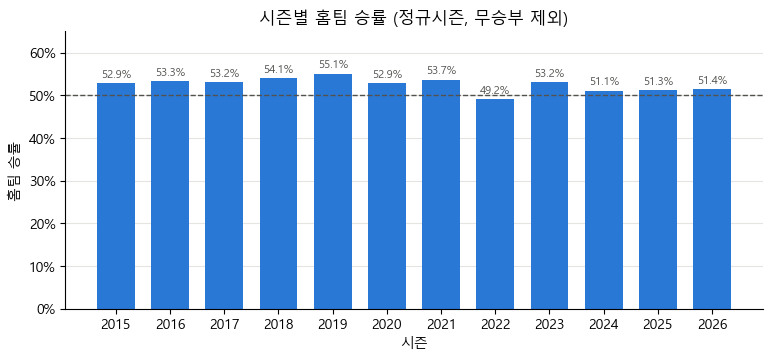

In [19]:
home_rate = final[~final["draw"]].groupby("season")["home_win"].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(home_rate.index, home_rate.values, color=BLUE, width=0.7)
ax.axhline(0.5, color=INK, linestyle="--", linewidth=1)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in home_rate.values], fontsize=8, color=INK, padding=2)
ax.set(title="시즌별 홈팀 승률 (정규시즌, 무승부 제외)", xlabel="시즌", ylabel="홈팀 승률",
       ylim=(0, 0.65), xticks=home_rate.index)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

**해석:** 12시즌 중 11시즌에서 홈팀 승률이 50%를 넘었어요(대부분 51~55%). 차이는 작지만 꾸준해서, 모델에게 "어느 팀이 홈팀인가"가 쓸모 있는 정보가 될 거라는 힌트예요. 2022년(49.2%)만 예외였어요.

### 8-2. 시즌별 무승부 수

무승부는 승패 예측에서 "누가 이겼다"로 맞힐 수 없는 경기라서, 얼마나 자주 나오는지 알아 둘 필요가 있어요.

**보는 법:** 막대 높이가 그 시즌 정규시즌의 무승부 경기 수예요(시즌당 전체 720경기).

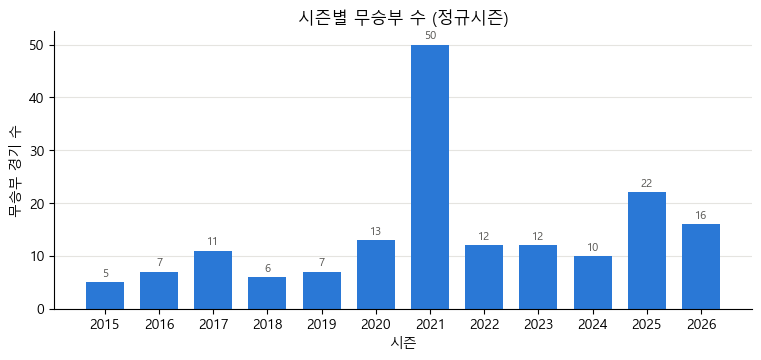

In [20]:
draws = final.groupby("season")["draw"].sum()

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(draws.index, draws.values, color=BLUE, width=0.7)
ax.bar_label(bars, fontsize=8, color=INK, padding=2)
ax.set(title="시즌별 무승부 수 (정규시즌)", xlabel="시즌", ylabel="무승부 경기 수", xticks=draws.index)
plt.show()

**해석:** 보통은 시즌당 5~22경기(전체의 3% 이하)로 드물지만, 2021년만 50경기로 크게 튀어요. 2021년 후반기에는 코로나19 상황 때문에 연장전 없이 9회까지만 경기를 했기 때문이에요.

### 8-3. 경기당 총득점 분포

한 경기에서 두 팀이 낸 점수를 더하면 보통 몇 점일까요? 2015~2026년 정규시즌 경기를 모두 합쳐서 **히스토그램**(값의 구간마다 경기가 몇 개인지 세어 막대로 그린 그래프)을 그려요. 점선은 중앙값(한 줄로 세웠을 때 딱 가운데 값)이에요.

**보는 법:** 막대 하나가 "총득점이 딱 그 점수인 경기 수"예요. 그래프 아래에 평균·중앙값·최빈값(가장 흔한 값)도 함께 적어 두었어요.

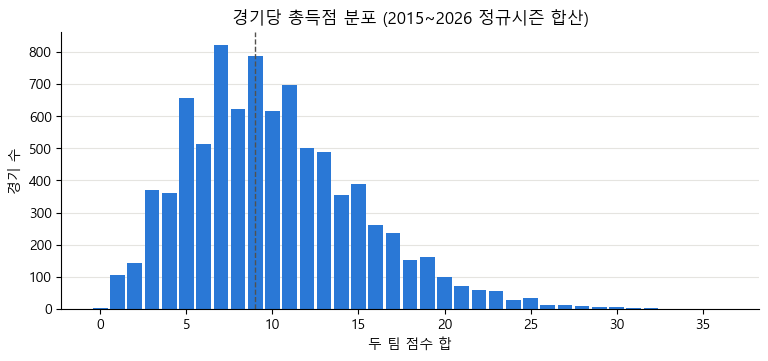

평균 10.1점 | 중앙값 9점 | 최빈값 7점 | 20점 이상 400경기 (4.6%) | 최다 36점


In [21]:
runs = final["total_runs"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(runs, bins=range(0, runs.max() + 2), align="left", rwidth=0.85, color=BLUE)
ax.axvline(runs.median(), color=INK, linestyle="--", linewidth=1)
ax.set(title="경기당 총득점 분포 (2015~2026 정규시즌 합산)", xlabel="두 팀 점수 합", ylabel="경기 수")
plt.show()

print(f"평균 {runs.mean():.1f}점 | 중앙값 {runs.median():.0f}점 | 최빈값 {runs.mode()[0]}점 | "
      f"20점 이상 {(runs >= 20).sum()}경기 ({(runs >= 20).mean():.1%}) | 최다 {runs.max()}점")

**해석:** 경기당 총득점은 평균 약 10점, 중앙값 9점이고 가장 흔한 건 7점이에요. 오른쪽으로 꼬리가 길어서 20점 이상 나는 난타전도 20경기 중 1경기꼴(4.6%)로 나와요.

## 9. 데이터 품질 메모

데이터를 쓰기 전에 알아 두어야 할 빈틈과 규칙을 모아 두었어요.

### 9-1. LIVE로 멈춘 경기

전체 시즌에서 `status`가 `LIVE`인 행을 찾아요. 목록을 손으로 적지 않고 데이터에서 바로 뽑기 때문에, 나중에 이런 경기가 늘거나 줄어도 이 표가 알아서 따라가요.

**출력 보는 법:** 점수는 사이트가 멈춘 순간의 점수예요. `regular`가 `False`인 2024-03-12 경기는 시범경기라 원래 학습에 쓰지 않아요.
나머지 4경기는 7번에서 본 정규시즌 경기들이에요. 수집기는 이틀 넘게 LIVE로 남은 경기를 경기 페이지로 다시 확인해서, 페이지가 "경기 종료"와 두 팀 점수를 모두 보여 줄 때만 FINAL로 바꿔요. 이 경기들은 그 조건을 끝내 채우지 못해서, 결과를 지어내지 않고 학습에서 빼요.

In [22]:
live = games.loc[games["status"] == "LIVE",
                 ["game_id", "date", "away_code", "home_code", "away_score", "home_score", "regular"]]
display(live.astype(SCORE_INT))

,game_id,date,away_code,home_code,away_score,home_score,regular
6329,9809,2022-05-25,LT,SK,1,9,True
7714,11192,2023-10-01,LG,OB,7,4,True
7809,11295,2024-03-12,OB,LT,0,1,False
9683,13352,2026-04-22,HH,LG,0,3,True
9937,13606,2026-06-19,SS,HH,3,3,True


### 9-2. 취소 경기는 언제 많을까?

비, 미세먼지, 폭염 같은 이유로 취소된 경기를 월별·사유별로 세어요(전체 시즌, 시범경기·포스트시즌 포함). 사유 이름은 알아보기 쉽게 우리말로 바꿔서 보여 드려요.

**출력 보는 법:** 행은 월, 열은 취소 사유, 칸은 취소된 경기 수예요. 맨 오른쪽 `합계`를 먼저 보시면 돼요.

In [23]:
REASON_KO = {"Rained Out": "우천", "Poor Field Conditions": "그라운드 사정", "Extreme Heat": "폭염",
             "Fine Dust": "미세먼지", "Cold Weather": "추위", "Strong Winds": "강풍", "Other": "기타"}

canceled = games[games["status"] == "CANCELED"]
by_month = pd.crosstab(canceled["date"].str[5:7].astype(int).rename("월"),
                       canceled["status_note"].map(REASON_KO).fillna("사유 없음").rename("사유"),
                       margins=True, margins_name="합계")
display(by_month)

사유,강풍,그라운드 사정,기타,미세먼지,사유 없음,우천,추위,폭염,합계
월,,,,,,,,,
3,0,1,1,4,13,44,11,0,74
4,0,1,10,6,5,86,0,0,108
5,0,6,10,8,4,102,0,0,130
6,0,6,2,0,0,109,0,0,117
7,0,14,39,0,0,148,0,0,201
8,0,10,0,0,9,141,0,34,194
9,2,2,0,0,2,103,0,0,109
10,0,0,0,0,22,17,0,0,39
11,0,0,0,0,13,2,0,0,15


**해석:** 장마철인 7~8월에 취소가 가장 많고(각각 약 200경기), 8월에는 폭염 취소도 보여요. 3월 취소(74경기)는 대부분 시범경기이고, 추위 때문에 취소된 경기는 이 시기에만 나와요.
`사유 없음`(68경기)은 주로 3월 시범경기와 10~11월 포스트시즌에 몰려 있어요. 포스트시즌 쪽은 시리즈가 일찍 끝나서 열릴 필요가 없어진 경기로 보여요.

### 9-3. 결측(빈 값) 처리 규칙

- **점수:** 취소되었거나 끝나지 않은 경기의 점수는 0이 아니라 `None`이에요. 0:0 무승부와 헷갈리면 안 되니까요.
- **박스스코어 숫자 칸:** `-`처럼 숫자가 아닌 칸은 `None`이에요(4번에서 이야기한 규칙).
- **우천 지연 표기:** 비 때문에 잠시 멈췄다가 다시 한 경기 중 몇 개는, 다 끝났는데도 경기 페이지에 "Delayed"(지연)가 남아 있어요. 파서는 이걸 "아직 안 끝남"으로 읽지만, 최종 점수와 FINAL 상태는 주간 일정 페이지에서 가져오기 때문에 경기 결과에는 문제가 없어요.

**출력 보는 법:** 첫 줄은 취소 경기가 모두 점수 `None`인지, 둘째 줄은 지금까지 모은 박스스코어에 `None` 숫자 칸이 몇 개인지(0이면 빈 칸 없이 깔끔하게 모였다는 뜻), 셋째 줄은 경기 페이지에 FINAL이 아닌 표기가 남아 있는 박스스코어 수예요.

In [24]:
print(f"취소 경기 {len(canceled)}개 중 점수가 None인 경기: {canceled['home_score'].isna().sum()}개")

none_cells = sum(v is None
                 for s in seasons for b in boxscores[s].values()
                 for kind in ("batting", "pitching") for side in ("away", "home")
                 for row in b[kind][side] for v in row.values())
print(f"박스스코어 전체에서 None인 숫자 칸: {none_cells}개")

not_final_pages = [gid for s in seasons for gid, b in boxscores[s].items() if b["status"] != "FINAL"]
week_status = games.set_index("game_id").loc[not_final_pages, "status"]
print(f"경기 페이지 표기가 FINAL이 아닌 박스스코어: {len(not_final_pages)}개 "
      f"(주간 일정에서는 {week_status.value_counts().to_dict()})")

취소 경기 987개 중 점수가 None인 경기: 987개


박스스코어 전체에서 None인 숫자 칸: 0개
경기 페이지 표기가 FINAL이 아닌 박스스코어: 19개 (주간 일정에서는 {'FINAL': 19})


### 9-4. 다시 잡힌 경기는 새 `game_id`를 받아요

취소된 경기는 나중에 다른 날로 다시 잡혀요(**재편성**). 이때 사이트는 같은 번호를 다시 쓰지 않고 **새 번호**(`game_id`)를 줘요.
그래서 취소된 날의 행은 `CANCELED`로 그대로 남고, 다시 치른 경기는 새 번호의 `FINAL` 행으로 따로 생겨요.

7번 표에서 정규시즌 취소가 시즌마다 40~135경기나 되는데도 `FINAL + LIVE`가 정확히 720이었던 게 바로 그 증거예요. 만약 재편성 경기가 같은 번호를 덮어썼다면 정규시즌 행 수는 720에 머물렀을 거예요.

**출력 보는 법:** 첫 줄은 전체 데이터에 같은 `game_id`가 두 번 나오지 않는지, 표는 시즌마다 `정규시즌 행 수 = 720 + 취소`인지 보여 줘요.
덕분에 경기를 셀 때 취소 행만 빼면 되고, 한 경기가 두 번 세어질 걱정은 없어요.

In [25]:
print("game_id가 모두 서로 다른가요?:", games["game_id"].is_unique)

rows_check = reg_table[["FINAL + LIVE", "CANCELED"]].copy()
rows_check["정규시즌 행 수"] = regular.groupby("season").size()
display(rows_check.T)

game_id가 모두 서로 다른가요?: True


season,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
status,,,,,,,,,,,,
FINAL + LIVE,720,720,720,720,720,720,720,720,720,720,720,720
CANCELED,81,63,40,41,59,68,135,49,93,78,102,72
정규시즌 행 수,801,783,760,761,779,788,855,769,813,798,822,792


## 10. 요약과 다음 이야기

### 오늘 확인한 것
- KBO 공개 API가 없어서, 규칙(robots.txt의 5초 간격)을 지키며 **MyKBOStats**에서 모았어요. 원본 HTML은 커밋하지 않고 파싱한 JSON만 저장소에 둬요.
- 주간 일정 페이지에서 경기 목록을, 경기 페이지에서 타자·투수 박스스코어를 뽑아요. 이닝은 반올림 오차가 없도록 **아웃 수**로 저장해요.
- 2015~2026년 12개 시즌이 모두 있고, 끝난 경기는 전부 박스스코어까지 짝이 맞아요.
- 정규시즌은 시즌마다 정확히 **720경기**예요. 사이트에서 LIVE로 멈춘 정규시즌 4경기는 결과를 지어내지 않고 학습에서 빼요.
- 홈팀은 대부분 시즌에 51~55% 정도로 조금 더 자주 이겨요. 무승부는 드물지만 2021년은 예외였고, 경기당 총득점은 평균 약 10점이에요.

### 다음 노트북: 02. 피처 만들기
이제 믿을 만한 경기 기록이 준비됐어요. 다음 노트북에서는 이 기록으로 **경기 전에 알 수 있는 정보**(시즌 승률, 최근 10경기 흐름, 득실점 차이 등)를 만들어서, 모델이 "오늘 누가 이길까?"를 배울 수 있는 재료(피처)로 바꿔 볼게요.